In [1]:
import os
import copy

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import DataLoader, Subset
from torchvision.datasets import ImageFolder
from torchvision import transforms

from sklearn.model_selection import train_test_split

In [2]:
ruta_dataset = "../dataset_cat"

transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

In [3]:
dataset = ImageFolder(
    root=ruta_dataset,
    transform=transform
)

print("Número de imágenes:", len(dataset))
print("Clases:", dataset.classes)
print("Etiquetas:", dataset.class_to_idx)

Número de imágenes: 1613
Clases: ['Abyssinian', 'Bengal', 'Bombay', 'British Shorthair', 'Egyptian Mau', 'Maine Coon', 'Persian', 'Ragdoll', 'Siamese', 'Sphynx']
Etiquetas: {'Abyssinian': 0, 'Bengal': 1, 'Bombay': 2, 'British Shorthair': 3, 'Egyptian Mau': 4, 'Maine Coon': 5, 'Persian': 6, 'Ragdoll': 7, 'Siamese': 8, 'Sphynx': 9}


Forma del tensor: torch.Size([3, 128, 128])
Etiqueta numérica: 0
Clase: Abyssinian


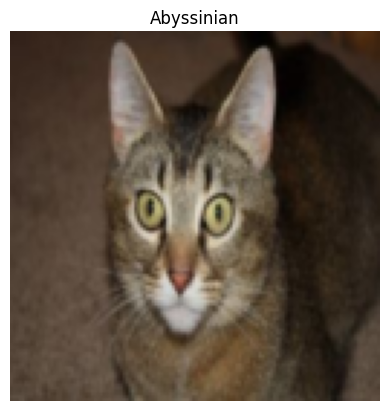

In [4]:
imagen, etiqueta = dataset[0]

print("Forma del tensor:", imagen.shape)
print("Etiqueta numérica:", etiqueta)
print("Clase:", dataset.classes[etiqueta])

plt.imshow(imagen.permute(1, 2, 0))
plt.title(dataset.classes[etiqueta])
plt.axis("off")
plt.show()

División train / validation / test


In [5]:
indices = np.arange(len(dataset))
etiquetas = dataset.targets

indices_train, indices_temp = train_test_split(
    indices,
    test_size=0.30,
    stratify=etiquetas,
    random_state=42
)

indices_val, indices_test = train_test_split(
    indices_temp,
    test_size=0.50,
    stratify=np.array(etiquetas)[indices_temp],
    random_state=42
)

Creamos subsets

In [6]:
train_dataset = Subset(dataset, indices_train)
val_dataset = Subset(dataset, indices_val)
test_dataset = Subset(dataset, indices_test)

print("Entrenamiento:", len(train_dataset))
print("Validación:", len(val_dataset))
print("Test:", len(test_dataset))

Entrenamiento: 1129
Validación: 242
Test: 242


Dataloaders

In [8]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

Comprobamos un batch

In [9]:
imagenes, etiquetas = next(iter(train_loader))

print("Forma imágenes:", imagenes.shape)
print("Forma etiquetas:", etiquetas.shape)
print("Etiquetas:", etiquetas)

Forma imágenes: torch.Size([32, 3, 128, 128])
Forma etiquetas: torch.Size([32])
Etiquetas: tensor([6, 7, 9, 9, 7, 1, 1, 0, 9, 0, 9, 3, 3, 6, 8, 6, 8, 6, 1, 5, 4, 7, 6, 6,
        2, 2, 0, 7, 7, 2, 6, 8])


# Experimentos de configuraciones CNN

## Configuración 1
Primera configuración utilizada como referencia inicial.

- 2 capas convolucionales
- Filtros: 16 → 32
- Kernel: 3x3
- MaxPooling: 2x2
- Capa oculta: 128 neuronas
- Dropout: 0.5
- Learning rate: 0.001
- Batch size: 32
- Máximo de épocas: 30
- Early stopping: paciencia 3

In [10]:
class CNN_Config1(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(32 * 32 * 32, 128)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)

        return x

In [11]:
model = CNN_Config1()

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

num_epochs = 30
paciencia = 3

mejor_val_loss = float("inf")
contador = 0
mejor_modelo = None

In [13]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

### Entrenamiento inicial
Primera prueba de 5 épocas para comprobar que la red aprende y que la pérdida de entrenamiento disminuye.

In [14]:
num_epochs = 5

for epoch in range(num_epochs):

    model.train()

    running_loss = 0.0

    for imagenes, etiquetas in train_loader:

        optimizer.zero_grad()

        salidas = model(imagenes)

        loss = criterion(salidas, etiquetas)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    loss_epoch = running_loss / len(train_loader)

    print(
        f"Época {epoch + 1}/{num_epochs} - "
        f"Loss: {loss_epoch:.4f}"
    )

Época 1/5 - Loss: 2.2403
Época 2/5 - Loss: 2.0947
Época 3/5 - Loss: 1.9479
Época 4/5 - Loss: 1.7676
Época 5/5 - Loss: 1.6500


### Entrenamiento con validación y parada temprana

In [15]:
model = CNN_Config1()

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

num_epochs = 30
paciencia = 3

mejor_val_loss = float("inf")
contador = 0
mejor_modelo = None

In [16]:
for epoch in range(num_epochs):

    model.train()

    running_loss = 0.0

    for imagenes, etiquetas in train_loader:

        optimizer.zero_grad()

        salidas = model(imagenes)

        loss = criterion(salidas, etiquetas)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)


    model.eval()

    val_loss = 0.0
    correctos = 0
    total = 0

    with torch.no_grad():

        for imagenes, etiquetas in val_loader:

            salidas = model(imagenes)

            loss = criterion(salidas, etiquetas)

            val_loss += loss.item()

            _, predicciones = torch.max(salidas, 1)

            total += etiquetas.size(0)
            correctos += (predicciones == etiquetas).sum().item()

    val_loss = val_loss / len(val_loader)
    val_accuracy = correctos / total


    print(
        f"Época {epoch + 1}/{num_epochs} - "
        f"Train Loss: {train_loss:.4f} - "
        f"Val Loss: {val_loss:.4f} - "
        f"Val Accuracy: {val_accuracy:.4f}"
    )


    if val_loss < mejor_val_loss:

        mejor_val_loss = val_loss
        mejor_modelo = copy.deepcopy(model.state_dict())
        contador = 0

    else:

        contador += 1

        if contador >= paciencia:

            print("Parada temprana")
            break

model.load_state_dict(mejor_modelo)

Época 1/30 - Train Loss: 2.3239 - Val Loss: 2.2767 - Val Accuracy: 0.1901
Época 2/30 - Train Loss: 2.2055 - Val Loss: 2.1211 - Val Accuracy: 0.2231
Época 3/30 - Train Loss: 2.0558 - Val Loss: 2.0389 - Val Accuracy: 0.2810
Época 4/30 - Train Loss: 1.9378 - Val Loss: 1.9206 - Val Accuracy: 0.3264
Época 5/30 - Train Loss: 1.7880 - Val Loss: 1.9123 - Val Accuracy: 0.3388
Época 6/30 - Train Loss: 1.6969 - Val Loss: 1.8766 - Val Accuracy: 0.3306
Época 7/30 - Train Loss: 1.5373 - Val Loss: 1.7877 - Val Accuracy: 0.3471
Época 8/30 - Train Loss: 1.3838 - Val Loss: 1.7774 - Val Accuracy: 0.3884
Época 9/30 - Train Loss: 1.2287 - Val Loss: 1.8179 - Val Accuracy: 0.4215
Época 10/30 - Train Loss: 1.0475 - Val Loss: 1.7479 - Val Accuracy: 0.4091
Época 11/30 - Train Loss: 0.9662 - Val Loss: 1.7957 - Val Accuracy: 0.4050
Época 12/30 - Train Loss: 0.7666 - Val Loss: 1.8802 - Val Accuracy: 0.4050
Época 13/30 - Train Loss: 0.6604 - Val Loss: 1.9905 - Val Accuracy: 0.4091
Parada temprana


<All keys matched successfully>

Configuración 1
- 2 capas convolucionales: 16 → 32 filtros
- Capa oculta: 128 neuronas
- Dropout: 0.5
- Learning rate: 0.001
- Batch size: 32
- Máximo de épocas: 30
- Early stopping: paciencia 3

Mejor Val Loss: 1.7479
Época del mejor Val Loss: 10
Val Accuracy en esa época: 40.91 %
Máxima Val Accuracy observada: 42.15 % en época 9
Parada temprana: época 13

## Configuración 2 - Aumento del número de filtros
Cambios respecto a la configuración anterior:
- Se mantienen 2 capas convolucionales
- Filtros: 16-32 → 32-64
- Capa oculta: 128 neuronas
- Dropout: 0.5
- Learning rate: 0.001
- Batch size: 32
- Máximo de épocas: 30
- Early stopping: paciencia 3

In [17]:
class CNN_Config2(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(64 * 32 * 32, 128)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)

        return x

In [18]:
model = CNN_Config2()

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

num_epochs = 30
paciencia = 3

mejor_val_loss = float("inf")
contador = 0
mejor_modelo = None

In [19]:
for epoch in range(num_epochs):

    model.train()

    running_loss = 0.0

    for imagenes, etiquetas in train_loader:

        optimizer.zero_grad()

        salidas = model(imagenes)

        loss = criterion(salidas, etiquetas)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)


    model.eval()

    val_loss = 0.0
    correctos = 0
    total = 0

    with torch.no_grad():

        for imagenes, etiquetas in val_loader:

            salidas = model(imagenes)

            loss = criterion(salidas, etiquetas)

            val_loss += loss.item()

            _, predicciones = torch.max(salidas, 1)

            total += etiquetas.size(0)
            correctos += (predicciones == etiquetas).sum().item()

    val_loss = val_loss / len(val_loader)
    val_accuracy = correctos / total


    print(
        f"Época {epoch + 1}/{num_epochs} - "
        f"Train Loss: {train_loss:.4f} - "
        f"Val Loss: {val_loss:.4f} - "
        f"Val Accuracy: {val_accuracy:.4f}"
    )


    if val_loss < mejor_val_loss:

        mejor_val_loss = val_loss
        mejor_modelo = copy.deepcopy(model.state_dict())
        contador = 0

    else:

        contador += 1

        if contador >= paciencia:

            print("Parada temprana")
            break

model.load_state_dict(mejor_modelo)

Época 1/30 - Train Loss: 2.4136 - Val Loss: 2.2861 - Val Accuracy: 0.1570
Época 2/30 - Train Loss: 2.2728 - Val Loss: 2.2291 - Val Accuracy: 0.1942
Época 3/30 - Train Loss: 2.1818 - Val Loss: 2.0928 - Val Accuracy: 0.1901
Época 4/30 - Train Loss: 2.0660 - Val Loss: 2.0109 - Val Accuracy: 0.2603
Época 5/30 - Train Loss: 1.9973 - Val Loss: 1.9698 - Val Accuracy: 0.3182
Época 6/30 - Train Loss: 1.9332 - Val Loss: 1.9227 - Val Accuracy: 0.3306
Época 7/30 - Train Loss: 1.8715 - Val Loss: 1.9444 - Val Accuracy: 0.3099
Época 8/30 - Train Loss: 1.7920 - Val Loss: 1.9099 - Val Accuracy: 0.3554
Época 9/30 - Train Loss: 1.6978 - Val Loss: 1.8456 - Val Accuracy: 0.3182
Época 10/30 - Train Loss: 1.5673 - Val Loss: 1.8339 - Val Accuracy: 0.3554
Época 11/30 - Train Loss: 1.4051 - Val Loss: 1.8673 - Val Accuracy: 0.3678
Época 12/30 - Train Loss: 1.2730 - Val Loss: 2.0453 - Val Accuracy: 0.3884
Época 13/30 - Train Loss: 1.1057 - Val Loss: 1.9525 - Val Accuracy: 0.3471
Parada temprana


<All keys matched successfully>

CONFIGURACIÓN 2

- 2 capas convolucionales
- Filtros: 32 → 64
- Capa oculta: 128
- Dropout: 0.5
- Learning rate: 0.001
- Batch size: 32
- Máximo épocas: 30
- Early stopping: paciencia 3

Mejor época: 10
Train Loss: 1.5673
Val Loss: 1.8339
Val Accuracy: 35.54 %
Parada temprana: época 13

## Configuración 3 - Aumento de la profundidad

Cambios respecto a la configuración base:
- Se añade una tercera capa convolucional
- Filtros: 16 → 32 → 64
- Capa oculta: 128 neuronas
- Dropout: 0.5
- Learning rate: 0.001
- Batch size: 32
- Máximo de épocas: 30
- Early stopping: paciencia 3

In [20]:
class CNN_Config3(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(64 * 16 * 16, 128)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)

        return x

In [21]:
model = CNN_Config3()

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

num_epochs = 30
paciencia = 3

mejor_val_loss = float("inf")
contador = 0
mejor_modelo = None

In [22]:
for epoch in range(num_epochs):

    model.train()

    running_loss = 0.0

    for imagenes, etiquetas in train_loader:

        optimizer.zero_grad()

        salidas = model(imagenes)

        loss = criterion(salidas, etiquetas)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)


    model.eval()

    val_loss = 0.0
    correctos = 0
    total = 0

    with torch.no_grad():

        for imagenes, etiquetas in val_loader:

            salidas = model(imagenes)

            loss = criterion(salidas, etiquetas)

            val_loss += loss.item()

            _, predicciones = torch.max(salidas, 1)

            total += etiquetas.size(0)
            correctos += (predicciones == etiquetas).sum().item()

    val_loss = val_loss / len(val_loader)
    val_accuracy = correctos / total


    print(
        f"Época {epoch + 1}/{num_epochs} - "
        f"Train Loss: {train_loss:.4f} - "
        f"Val Loss: {val_loss:.4f} - "
        f"Val Accuracy: {val_accuracy:.4f}"
    )


    if val_loss < mejor_val_loss:

        mejor_val_loss = val_loss
        mejor_modelo = copy.deepcopy(model.state_dict())
        contador = 0

    else:

        contador += 1

        if contador >= paciencia:

            print("Parada temprana")
            break

model.load_state_dict(mejor_modelo)

Época 1/30 - Train Loss: 2.3010 - Val Loss: 2.2401 - Val Accuracy: 0.1901
Época 2/30 - Train Loss: 2.1610 - Val Loss: 2.1065 - Val Accuracy: 0.2025
Época 3/30 - Train Loss: 2.0502 - Val Loss: 2.0682 - Val Accuracy: 0.2727
Época 4/30 - Train Loss: 1.9930 - Val Loss: 2.0117 - Val Accuracy: 0.2645
Época 5/30 - Train Loss: 1.9486 - Val Loss: 1.9717 - Val Accuracy: 0.2769
Época 6/30 - Train Loss: 1.8560 - Val Loss: 1.9352 - Val Accuracy: 0.2810
Época 7/30 - Train Loss: 1.7678 - Val Loss: 1.8980 - Val Accuracy: 0.3099
Época 8/30 - Train Loss: 1.6559 - Val Loss: 1.8258 - Val Accuracy: 0.3182
Época 9/30 - Train Loss: 1.5696 - Val Loss: 1.9588 - Val Accuracy: 0.3058
Época 10/30 - Train Loss: 1.4290 - Val Loss: 1.8656 - Val Accuracy: 0.3595
Época 11/30 - Train Loss: 1.2688 - Val Loss: 1.8576 - Val Accuracy: 0.3843
Parada temprana


<All keys matched successfully>

CONFIGURACIÓN 3

- 3 capas convolucionales
- Filtros: 16 → 32 → 64
- Capa oculta: 128 neuronas
- Dropout: 0.5
- Learning rate: 0.001
- Batch size: 32
- Máximo épocas: 30
- Early stopping: paciencia 3

Mejor época: 8
Train Loss: 1.6559
Val Loss: 1.8258
Val Accuracy: 31.82 %
Máxima Val Accuracy observada: 38.43 % (época 11)
Parada temprana: época 11

## Configuración 4 - Aumento de neuronas en la capa oculta

Cambios respecto a la configuración 3:
- Se mantienen 3 capas convolucionales
- Filtros: 16 → 32 → 64
- Capa oculta: 128 → 256 neuronas
- Dropout: 0.5
- Learning rate: 0.001
- Batch size: 32
- Máximo de épocas: 30
- Early stopping: paciencia 3

In [23]:
class CNN_Config4(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(64 * 16 * 16, 256)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)

        return x

In [24]:
model = CNN_Config4()

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

num_epochs = 30
paciencia = 3

mejor_val_loss = float("inf")
contador = 0
mejor_modelo = None

In [25]:
for epoch in range(num_epochs):

    model.train()

    running_loss = 0.0

    for imagenes, etiquetas in train_loader:

        optimizer.zero_grad()

        salidas = model(imagenes)

        loss = criterion(salidas, etiquetas)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)


    model.eval()

    val_loss = 0.0
    correctos = 0
    total = 0

    with torch.no_grad():

        for imagenes, etiquetas in val_loader:

            salidas = model(imagenes)

            loss = criterion(salidas, etiquetas)

            val_loss += loss.item()

            _, predicciones = torch.max(salidas, 1)

            total += etiquetas.size(0)
            correctos += (predicciones == etiquetas).sum().item()

    val_loss = val_loss / len(val_loader)
    val_accuracy = correctos / total


    print(
        f"Época {epoch + 1}/{num_epochs} - "
        f"Train Loss: {train_loss:.4f} - "
        f"Val Loss: {val_loss:.4f} - "
        f"Val Accuracy: {val_accuracy:.4f}"
    )


    if val_loss < mejor_val_loss:

        mejor_val_loss = val_loss
        mejor_modelo = copy.deepcopy(model.state_dict())
        contador = 0

    else:

        contador += 1

        if contador >= paciencia:

            print("Parada temprana")
            break

model.load_state_dict(mejor_modelo)

Época 1/30 - Train Loss: 2.2652 - Val Loss: 2.1564 - Val Accuracy: 0.2107
Época 2/30 - Train Loss: 2.0734 - Val Loss: 2.0446 - Val Accuracy: 0.2521
Época 3/30 - Train Loss: 2.0010 - Val Loss: 2.0186 - Val Accuracy: 0.2562
Época 4/30 - Train Loss: 1.8856 - Val Loss: 1.9090 - Val Accuracy: 0.3017
Época 5/30 - Train Loss: 1.7626 - Val Loss: 1.9168 - Val Accuracy: 0.3512
Época 6/30 - Train Loss: 1.6526 - Val Loss: 1.8492 - Val Accuracy: 0.3760
Época 7/30 - Train Loss: 1.5077 - Val Loss: 1.8033 - Val Accuracy: 0.3512
Época 8/30 - Train Loss: 1.3489 - Val Loss: 1.8356 - Val Accuracy: 0.3554
Época 9/30 - Train Loss: 1.1898 - Val Loss: 1.8382 - Val Accuracy: 0.3884
Época 10/30 - Train Loss: 1.0879 - Val Loss: 1.7604 - Val Accuracy: 0.4339
Época 11/30 - Train Loss: 0.8873 - Val Loss: 1.8502 - Val Accuracy: 0.4339
Época 12/30 - Train Loss: 0.7869 - Val Loss: 1.9215 - Val Accuracy: 0.4174
Época 13/30 - Train Loss: 0.6591 - Val Loss: 2.0583 - Val Accuracy: 0.4380
Parada temprana


<All keys matched successfully>

CONFIGURACIÓN 4

- 3 capas convolucionales
- Filtros: 16 → 32 → 64
- Capa oculta: 256 neuronas
- Dropout: 0.5
- Learning rate: 0.001
- Batch size: 32
- Máximo épocas: 30
- Early stopping: paciencia 3

Mejor época: 10
Train Loss: 1.0879
Val Loss: 1.7604
Val Accuracy: 43.39 %
Máxima Val Accuracy observada: 43.80 % en época 13
Parada temprana: época 13

## Configuración 5 - Reducción del learning rate

Cambios respecto a la configuración 4:
- Se mantienen 3 capas convolucionales
- Filtros: 16 → 32 → 64
- Capa oculta: 256 neuronas
- Dropout: 0.5
- Learning rate: 0.001 → 0.0005
- Batch size: 32
- Máximo de épocas: 30
- Early stopping: paciencia 3

In [26]:
class CNN_Config5(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(64 * 16 * 16, 256)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)

        return x

In [30]:
model = CNN_Config5()

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0005
)

num_epochs = 30
paciencia = 3

mejor_val_loss = float("inf")
contador = 0
mejor_modelo = None

In [31]:
for epoch in range(num_epochs):

    model.train()

    running_loss = 0.0

    for imagenes, etiquetas in train_loader:

        optimizer.zero_grad()

        salidas = model(imagenes)

        loss = criterion(salidas, etiquetas)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)


    model.eval()

    val_loss = 0.0
    correctos = 0
    total = 0

    with torch.no_grad():

        for imagenes, etiquetas in val_loader:

            salidas = model(imagenes)

            loss = criterion(salidas, etiquetas)

            val_loss += loss.item()

            _, predicciones = torch.max(salidas, 1)

            total += etiquetas.size(0)
            correctos += (predicciones == etiquetas).sum().item()

    val_loss = val_loss / len(val_loader)
    val_accuracy = correctos / total


    print(
        f"Época {epoch + 1}/{num_epochs} - "
        f"Train Loss: {train_loss:.4f} - "
        f"Val Loss: {val_loss:.4f} - "
        f"Val Accuracy: {val_accuracy:.4f}"
    )


    if val_loss < mejor_val_loss:

        mejor_val_loss = val_loss
        mejor_modelo = copy.deepcopy(model.state_dict())
        contador = 0

    else:

        contador += 1

        if contador >= paciencia:

            print("Parada temprana")
            break

model.load_state_dict(mejor_modelo)

Época 1/30 - Train Loss: 2.2640 - Val Loss: 2.1509 - Val Accuracy: 0.2025
Época 2/30 - Train Loss: 2.0988 - Val Loss: 2.0750 - Val Accuracy: 0.2397
Época 3/30 - Train Loss: 1.9764 - Val Loss: 1.9942 - Val Accuracy: 0.3099
Época 4/30 - Train Loss: 1.8670 - Val Loss: 1.8946 - Val Accuracy: 0.3306
Época 5/30 - Train Loss: 1.7067 - Val Loss: 1.9463 - Val Accuracy: 0.3430
Época 6/30 - Train Loss: 1.6076 - Val Loss: 1.7955 - Val Accuracy: 0.3430
Época 7/30 - Train Loss: 1.4876 - Val Loss: 1.7292 - Val Accuracy: 0.3760
Época 8/30 - Train Loss: 1.3606 - Val Loss: 1.7519 - Val Accuracy: 0.3678
Época 9/30 - Train Loss: 1.2443 - Val Loss: 1.7272 - Val Accuracy: 0.3802
Época 10/30 - Train Loss: 1.0768 - Val Loss: 1.8192 - Val Accuracy: 0.4050
Época 11/30 - Train Loss: 1.0105 - Val Loss: 1.8473 - Val Accuracy: 0.3884
Época 12/30 - Train Loss: 0.8480 - Val Loss: 1.9964 - Val Accuracy: 0.3926
Parada temprana


<All keys matched successfully>

CONFIGURACIÓN 5

- 3 capas convolucionales
- Filtros: 16 → 32 → 64
- Capa oculta: 256 neuronas
- Dropout: 0.5
- Learning rate: 0.0005
- Batch size: 32
- Máximo épocas: 30
- Early stopping: paciencia 3

Mejor época: 9
Train Loss: 1.2443
Val Loss: 1.7272
Val Accuracy: 38.02 %
Máxima Val Accuracy observada: 40.50 % en época 10
Parada temprana: época 12

## Configuración 6 - CNN avanzada

Se prueba una arquitectura CNN más avanzada incorporando varias técnicas adicionales respecto a las configuraciones anteriores:

- 3 capas convolucionales con 32 → 64 → 128 filtros
- Batch Normalization después de cada convolución
- Adaptive Average Pooling
- Capa oculta de 128 neuronas
- Dropout de 0.5
- Learning rate de 0.0005
- Regularización mediante weight decay
- Scheduler para reducir automáticamente el learning rate
- Early stopping con paciencia 8

CONFIGURACIÓN 6 - CNN avanzada

Cambios principales respecto a las configuraciones manuales:

- Se aumenta el número de filtros hasta 32-64-128.
- Se incorpora Batch Normalization después de cada convolución para estabilizar el aprendizaje.
- Se incorpora Adaptive Average Pooling para reducir los mapas de características a 4x4 antes de la capa completamente conectada.
- Se mantiene Dropout = 0.5.
- La capa oculta tiene 128 neuronas.

La salida de la tercera capa convolucional es 128x16x16.
AdaptiveAvgPool la transforma en 128x4x4.
Por tanto, la capa completamente conectada recibe 2048 características.

In [47]:
class CNN_Config6(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        self.pool = nn.MaxPool2d(2, 2)

        self.global_pool = nn.AdaptiveAvgPool2d((4, 4))

        self.fc1 = nn.Linear(128 * 4 * 4, 128)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))

        x = self.global_pool(x)

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)

        return x

In [48]:
import copy
import time

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

model = CNN_Config6().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0005,
    weight_decay=0.0005
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

max_epochs = 50
patience = 8
min_delta = 0.001

best_val_loss = float("inf")
best_val_acc = 0.0
best_epoch = 0
best_weights = copy.deepcopy(model.state_dict())
epochs_without_improvement = 0

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

start_time = time.time()

Dispositivo: cpu


In [49]:
for epoch in range(max_epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for imagenes, etiquetas in train_loader:

        imagenes = imagenes.to(device)
        etiquetas = etiquetas.to(device)

        optimizer.zero_grad()

        salidas = model(imagenes)

        loss = criterion(salidas, etiquetas)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * imagenes.size(0)

        predicciones = salidas.argmax(dim=1)

        correct += (predicciones == etiquetas).sum().item()
        total += etiquetas.size(0)

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total


    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for imagenes, etiquetas in val_loader:

            imagenes = imagenes.to(device)
            etiquetas = etiquetas.to(device)

            salidas = model(imagenes)

            loss = criterion(salidas, etiquetas)

            val_running_loss += loss.item() * imagenes.size(0)

            predicciones = salidas.argmax(dim=1)

            val_correct += (predicciones == etiquetas).sum().item()
            val_total += etiquetas.size(0)

    val_loss = val_running_loss / val_total
    val_accuracy = 100 * val_correct / val_total


    scheduler.step(val_loss)


    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)


    print(
        f"Época {epoch + 1:02d}/{max_epochs} - "
        f"Train Loss: {train_loss:.4f} - "
        f"Val Loss: {val_loss:.4f} - "
        f"Train Accuracy: {train_accuracy:.2f}% - "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )


    if val_loss < best_val_loss - min_delta:

        best_val_loss = val_loss
        best_val_acc = val_accuracy
        best_epoch = epoch + 1

        best_weights = copy.deepcopy(model.state_dict())

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1


    if epochs_without_improvement >= patience:

        print("Parada temprana")
        break


model.load_state_dict(best_weights)

Época 01/50 - Train Loss: 2.1918 - Val Loss: 2.2800 - Train Accuracy: 19.93% - Val Accuracy: 14.05%
Época 02/50 - Train Loss: 1.9255 - Val Loss: 1.8730 - Train Accuracy: 30.74% - Val Accuracy: 30.17%
Época 03/50 - Train Loss: 1.8238 - Val Loss: 1.7511 - Train Accuracy: 36.05% - Val Accuracy: 38.43%
Época 04/50 - Train Loss: 1.7313 - Val Loss: 1.7986 - Train Accuracy: 37.20% - Val Accuracy: 29.75%
Época 05/50 - Train Loss: 1.6130 - Val Loss: 1.6100 - Train Accuracy: 42.07% - Val Accuracy: 40.91%
Época 06/50 - Train Loss: 1.5437 - Val Loss: 1.6032 - Train Accuracy: 43.49% - Val Accuracy: 43.39%
Época 07/50 - Train Loss: 1.4930 - Val Loss: 1.5691 - Train Accuracy: 47.30% - Val Accuracy: 42.98%
Época 08/50 - Train Loss: 1.4195 - Val Loss: 1.5810 - Train Accuracy: 49.78% - Val Accuracy: 38.84%
Época 09/50 - Train Loss: 1.3626 - Val Loss: 1.5625 - Train Accuracy: 51.99% - Val Accuracy: 45.04%
Época 10/50 - Train Loss: 1.3401 - Val Loss: 1.4963 - Train Accuracy: 51.73% - Val Accuracy: 44.21%


<All keys matched successfully>

In [50]:
elapsed = (time.time() - start_time) / 60

print("\nEntrenamiento terminado")
print("Mejor época:", best_epoch)
print(f"Mejor pérdida de validación: {best_val_loss:.4f}")
print(f"Precisión de validación en esa época: {best_val_acc:.2f}%")
print(f"Tiempo total: {elapsed:.2f} minutos")


Entrenamiento terminado
Mejor época: 33
Mejor pérdida de validación: 1.2303
Precisión de validación en esa época: 54.13%
Tiempo total: 11.34 minutos


CONFIGURACIÓN 6 - CNN avanzada

- 3 capas convolucionales
- Filtros: 32 → 64 → 128
- Batch Normalization tras cada convolución
- Adaptive Average Pooling a 4x4
- Capa oculta: 128 neuronas
- Dropout: 0.5
- Learning rate inicial: 0.0005
- Weight decay: 0.0005
- Scheduler ReduceLROnPlateau
- Máximo épocas: 35
- Early stopping: paciencia 8
- Min delta: 0.001

Mejor época: 35
Train Loss: 0.8795
Val Loss: 1.3287
Train Accuracy: 70.95 %
Val Accuracy: 54.13 %
Tiempo total: 8.45 minutos

Control adicional de C6

Se repitió la Configuración 6 aumentando únicamente el máximo de épocas
de 35 a 50 para comprobar si el mejor resultado de C7 podía deberse a
un mayor tiempo de entrenamiento.

Resultados:
- Mejor época: 33
- Train Loss: 0.6667
- Val Loss: 1.2303
- Train Accuracy: 77.86 %
- Val Accuracy: 54.13 %
- Máxima Val Accuracy observada: 57.44 % (época 34)
- Parada temprana: época 41

Conclusión:
La ampliación del entrenamiento mejoró el resultado original de C6,
pero mantuvo una diferencia considerable entre entrenamiento y
validación. C7 obtuvo una pérdida de validación ligeramente inferior
y redujo notablemente esta diferencia, por lo que el data augmentation
parece ayudar principalmente a reducir el sobreajuste.

## Configuración 7 - CNN avanzada con Data Augmentation

Se mantiene la arquitectura de la Configuración 6 y se incorpora aumentado de datos únicamente en el conjunto de entrenamiento.

Transformaciones utilizadas:
- Volteo horizontal aleatorio
- Rotación aleatoria pequeña
- Variaciones de brillo, contraste y saturación
- Pequeñas traslaciones y cambios de escala

Validación y test se mantienen sin aumentado de datos.

CONFIGURACIÓN 7

Objetivo:
Reducir el sobreajuste observado en la Configuración 6 mediante aumentado de datos.

Arquitectura:
Se mantiene la CNN de la Configuración 6.

Data Augmentation aplicado únicamente a entrenamiento:
- RandomHorizontalFlip (p=0.5)
- RandomRotation (10 grados)
- ColorJitter (brightness=0.2, contrast=0.2, saturation=0.2)
- RandomAffine con pequeñas traslaciones y escalado

Validación y test:
Resize 128x128 + ToTensor, sin transformaciones aleatorias.

Se mantienen los mismos índices train/validation/test que en las configuraciones anteriores.

In [36]:
transform_train = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.05, 0.05),
        scale=(0.95, 1.05)
    ),
    transforms.ToTensor()
])

transform_eval = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

In [38]:
dataset_train_aug = ImageFolder(
    root=ruta_dataset,
    transform=transform_train
)

dataset_eval = ImageFolder(
    root=ruta_dataset,
    transform=transform_eval
)

In [39]:
train_dataset_aug = Subset(
    dataset_train_aug,
    indices_train
)

val_dataset_aug = Subset(
    dataset_eval,
    indices_val
)

test_dataset_aug = Subset(
    dataset_eval,
    indices_test
)

In [40]:
train_loader_aug = DataLoader(
    train_dataset_aug,
    batch_size=32,
    shuffle=True
)

val_loader_aug = DataLoader(
    val_dataset_aug,
    batch_size=32,
    shuffle=False
)

test_loader_aug = DataLoader(
    test_dataset_aug,
    batch_size=32,
    shuffle=False
)

In [44]:
model = CNN_Config6().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0005,
    weight_decay=0.0005
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

max_epochs = 50
patience = 8
min_delta = 0.001

best_val_loss = float("inf")
best_val_acc = 0.0
best_epoch = 0
best_weights = copy.deepcopy(model.state_dict())

epochs_without_improvement = 0

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

start_time = time.time()

In [45]:
for epoch in range(max_epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for imagenes, etiquetas in train_loader_aug:

        imagenes = imagenes.to(device)
        etiquetas = etiquetas.to(device)

        optimizer.zero_grad()

        salidas = model(imagenes)

        loss = criterion(salidas, etiquetas)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * imagenes.size(0)

        predicciones = salidas.argmax(dim=1)

        correct += (predicciones == etiquetas).sum().item()
        total += etiquetas.size(0)

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total


    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for imagenes, etiquetas in val_loader_aug:

            imagenes = imagenes.to(device)
            etiquetas = etiquetas.to(device)

            salidas = model(imagenes)

            loss = criterion(salidas, etiquetas)

            val_running_loss += loss.item() * imagenes.size(0)

            predicciones = salidas.argmax(dim=1)

            val_correct += (predicciones == etiquetas).sum().item()
            val_total += etiquetas.size(0)

    val_loss = val_running_loss / val_total
    val_accuracy = 100 * val_correct / val_total


    scheduler.step(val_loss)


    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)


    print(
        f"Época {epoch + 1:02d}/{max_epochs} - "
        f"Train Loss: {train_loss:.4f} - "
        f"Val Loss: {val_loss:.4f} - "
        f"Train Accuracy: {train_accuracy:.2f}% - "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )


    if val_loss < best_val_loss - min_delta:

        best_val_loss = val_loss
        best_val_acc = val_accuracy
        best_epoch = epoch + 1

        best_weights = copy.deepcopy(model.state_dict())

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1


    if epochs_without_improvement >= patience:

        print("Parada temprana")
        break


model.load_state_dict(best_weights)

Época 01/50 - Train Loss: 2.2504 - Val Loss: 2.2052 - Train Accuracy: 15.06% - Val Accuracy: 17.77%
Época 02/50 - Train Loss: 2.0389 - Val Loss: 1.8998 - Train Accuracy: 27.72% - Val Accuracy: 34.71%
Época 03/50 - Train Loss: 1.8929 - Val Loss: 1.8500 - Train Accuracy: 31.00% - Val Accuracy: 33.88%
Época 04/50 - Train Loss: 1.8308 - Val Loss: 1.7537 - Train Accuracy: 34.99% - Val Accuracy: 37.19%
Época 05/50 - Train Loss: 1.7616 - Val Loss: 1.6927 - Train Accuracy: 36.49% - Val Accuracy: 38.84%
Época 06/50 - Train Loss: 1.7166 - Val Loss: 1.7058 - Train Accuracy: 38.62% - Val Accuracy: 38.84%
Época 07/50 - Train Loss: 1.6774 - Val Loss: 1.6206 - Train Accuracy: 40.48% - Val Accuracy: 41.32%
Época 08/50 - Train Loss: 1.6502 - Val Loss: 1.6186 - Train Accuracy: 42.43% - Val Accuracy: 41.32%
Época 09/50 - Train Loss: 1.6096 - Val Loss: 1.7100 - Train Accuracy: 43.05% - Val Accuracy: 39.26%
Época 10/50 - Train Loss: 1.6100 - Val Loss: 1.5556 - Train Accuracy: 43.05% - Val Accuracy: 45.45%


<All keys matched successfully>

In [46]:
elapsed = (time.time() - start_time) / 60

print("\nEntrenamiento terminado")
print("Mejor época:", best_epoch)
print(f"Mejor pérdida de validación: {best_val_loss:.4f}")
print(f"Precisión de validación en esa época: {best_val_acc:.2f}%")
print(f"Tiempo total: {elapsed:.2f} minutos")


Entrenamiento terminado
Mejor época: 38
Mejor pérdida de validación: 1.2192
Precisión de validación en esa época: 54.96%
Tiempo total: 11.06 minutos


CONFIGURACIÓN 7 - Data Augmentation

Arquitectura:
La misma CNN avanzada que C6.

Cambio:
Se incorpora Data Augmentation únicamente en entrenamiento.

Mejor época: 38
Train Loss: 1.1267
Val Loss: 1.2192
Train Accuracy: 59.08 %
Val Accuracy: 54.96 %

Máxima Val Accuracy observada:
56.61 % en época 44

Parada temprana:
Época 46

Observación:
Se reduce considerablemente la diferencia entre precisión de
entrenamiento y validación, lo que indica menor sobreajuste.

## Configuración 8 - Aumento de la resolución de entrada

Se mantiene la arquitectura y el aumentado de datos de la Configuración 7.

Único cambio:
- Resolución de entrada: 128x128 → 160x160

El objetivo es conservar mayor información visual de las imágenes para facilitar la identificación de características finas entre las distintas razas.

In [51]:
transform_train_160 = transforms.Compose([
    transforms.Resize((160, 160)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.05, 0.05),
        scale=(0.95, 1.05)
    ),
    transforms.ToTensor()
])

transform_eval_160 = transforms.Compose([
    transforms.Resize((160, 160)),
    transforms.ToTensor()
])

In [52]:
dataset_train_160 = ImageFolder(
    root=ruta_dataset,
    transform=transform_train_160
)

dataset_eval_160 = ImageFolder(
    root=ruta_dataset,
    transform=transform_eval_160
)

In [53]:
train_dataset_160 = Subset(
    dataset_train_160,
    indices_train
)

val_dataset_160 = Subset(
    dataset_eval_160,
    indices_val
)

test_dataset_160 = Subset(
    dataset_eval_160,
    indices_test
)

In [54]:
train_loader_160 = DataLoader(
    train_dataset_160,
    batch_size=32,
    shuffle=True
)

val_loader_160 = DataLoader(
    val_dataset_160,
    batch_size=32,
    shuffle=False
)

test_loader_160 = DataLoader(
    test_dataset_160,
    batch_size=32,
    shuffle=False
)

In [57]:
model = CNN_Config6().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0005,
    weight_decay=0.0005
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

max_epochs = 70
patience = 8
min_delta = 0.001

best_val_loss = float("inf")
best_val_acc = 0.0
best_epoch = 0

best_weights = copy.deepcopy(model.state_dict())

epochs_without_improvement = 0

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

start_time = time.time()

In [58]:
for epoch in range(max_epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for imagenes, etiquetas in train_loader_160:

        imagenes = imagenes.to(device)
        etiquetas = etiquetas.to(device)

        optimizer.zero_grad()

        salidas = model(imagenes)

        loss = criterion(salidas, etiquetas)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * imagenes.size(0)

        predicciones = salidas.argmax(dim=1)

        correct += (predicciones == etiquetas).sum().item()
        total += etiquetas.size(0)

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total


    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for imagenes, etiquetas in val_loader_160:

            imagenes = imagenes.to(device)
            etiquetas = etiquetas.to(device)

            salidas = model(imagenes)

            loss = criterion(salidas, etiquetas)

            val_running_loss += loss.item() * imagenes.size(0)

            predicciones = salidas.argmax(dim=1)

            val_correct += (predicciones == etiquetas).sum().item()
            val_total += etiquetas.size(0)

    val_loss = val_running_loss / val_total
    val_accuracy = 100 * val_correct / val_total


    scheduler.step(val_loss)


    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)


    print(
        f"Época {epoch + 1:02d}/{max_epochs} - "
        f"Train Loss: {train_loss:.4f} - "
        f"Val Loss: {val_loss:.4f} - "
        f"Train Accuracy: {train_accuracy:.2f}% - "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )


    if val_loss < best_val_loss - min_delta:

        best_val_loss = val_loss
        best_val_acc = val_accuracy
        best_epoch = epoch + 1

        best_weights = copy.deepcopy(model.state_dict())

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1


    if epochs_without_improvement >= patience:

        print("Parada temprana")
        break


model.load_state_dict(best_weights)

Época 01/70 - Train Loss: 2.2355 - Val Loss: 2.2010 - Train Accuracy: 17.09% - Val Accuracy: 19.42%
Época 02/70 - Train Loss: 1.9994 - Val Loss: 1.8498 - Train Accuracy: 26.75% - Val Accuracy: 33.88%
Época 03/70 - Train Loss: 1.8848 - Val Loss: 1.7760 - Train Accuracy: 31.80% - Val Accuracy: 35.12%
Época 04/70 - Train Loss: 1.8432 - Val Loss: 1.7736 - Train Accuracy: 33.22% - Val Accuracy: 33.47%
Época 05/70 - Train Loss: 1.7446 - Val Loss: 1.7104 - Train Accuracy: 36.58% - Val Accuracy: 35.95%
Época 06/70 - Train Loss: 1.7489 - Val Loss: 1.6715 - Train Accuracy: 37.47% - Val Accuracy: 42.15%
Época 07/70 - Train Loss: 1.7315 - Val Loss: 1.6451 - Train Accuracy: 38.18% - Val Accuracy: 34.71%
Época 08/70 - Train Loss: 1.6713 - Val Loss: 1.7068 - Train Accuracy: 40.12% - Val Accuracy: 42.15%
Época 09/70 - Train Loss: 1.5999 - Val Loss: 1.6205 - Train Accuracy: 41.81% - Val Accuracy: 40.08%
Época 10/70 - Train Loss: 1.6745 - Val Loss: 1.6929 - Train Accuracy: 40.48% - Val Accuracy: 36.36%


<All keys matched successfully>

CONFIGURACIÓN 8 - Resolución 160x160

Arquitectura:
- CNN avanzada de C6/C7
- Filtros: 32 → 64 → 128
- Batch Normalization
- Adaptive Average Pooling 4x4
- FC: 128
- Dropout: 0.5

Entrenamiento:
- Data Augmentation
- Resolución: 160x160
- Learning rate: 0.0005
- Weight decay: 0.0005
- Scheduler ReduceLROnPlateau
- Early stopping: paciencia 8
- Máximo épocas: 50

Mejor época: 50
Train Loss: 1.0194
Val Loss: 1.1803
Train Accuracy: 65.19 %
Val Accuracy: 55.79 %

Máxima Val Accuracy observada:
58.68 % en época 46

Observación:
La resolución de 160x160 mejora tanto la pérdida de validación como
la precisión máxima respecto a la configuración 7. Además, la mejor
pérdida de validación se alcanza en la última época, por lo que el
modelo podría seguir mejorando con más entrenamiento.

Control C8 - entrenamiento ampliado a 70 épocas

Se amplió el máximo de entrenamiento de 50 a 70 épocas manteniendo
sin cambios la arquitectura y los hiperparámetros.

Resultados:
- Mejor época: 70
- Train Loss: 0.9656
- Val Loss: 1.1283
- Train Accuracy: 66.52 %
- Val Accuracy: 57.85 %
- Máxima Val Accuracy: 57.85 %

Conclusión:
La ampliación del entrenamiento redujo la pérdida de validación
respecto al entrenamiento de 50 épocas, aunque la precisión comenzó
a estabilizarse alrededor del 56-58 %. Por tanto, aumentar únicamente
el número de épocas no parece suficiente para conseguir una mejora
sustancial adicional.

In [59]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_true = []
y_pred = []

model.eval()

with torch.no_grad():

    for imagenes, etiquetas in val_loader_160:

        imagenes = imagenes.to(device)
        etiquetas = etiquetas.to(device)

        salidas = model(imagenes)

        predicciones = salidas.argmax(dim=1)

        y_true.extend(etiquetas.cpu().numpy())
        y_pred.extend(predicciones.cpu().numpy())

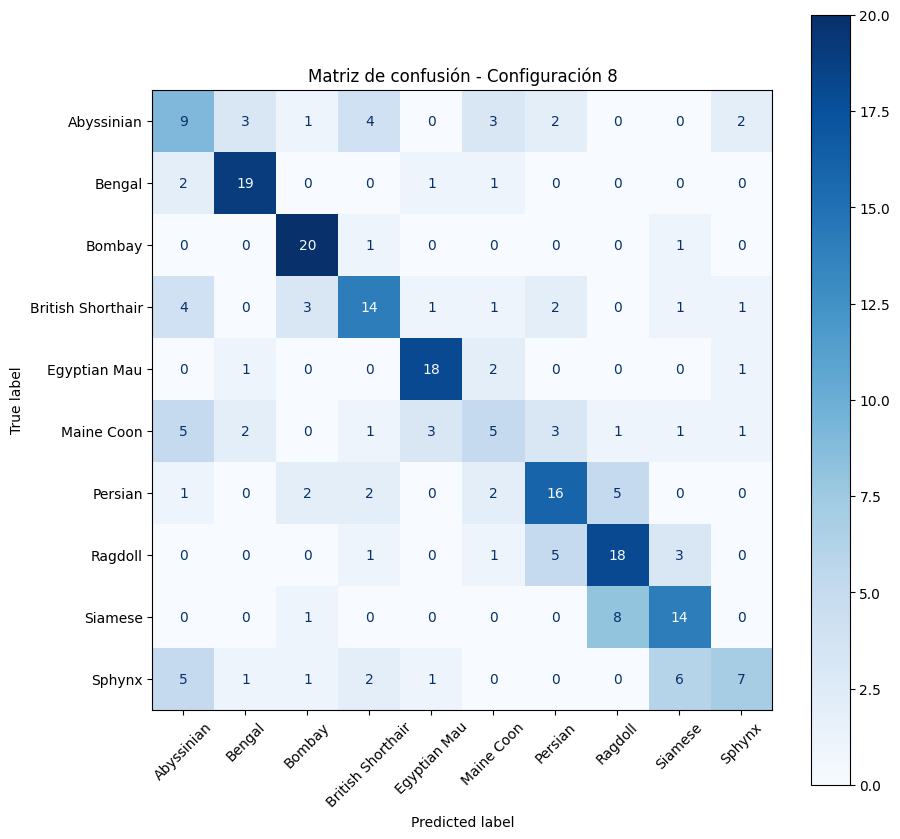

In [61]:
fig, ax = plt.subplots(figsize=(10, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=dataset.classes
)

disp.plot(
    xticks_rotation=45,
    cmap="Blues",
    ax=ax
)

plt.title("Matriz de confusión - Configuración 8")
plt.show()

Análisis de la matriz de confusión de C8

La precisión global de validación fue del 57,85 %, pero el rendimiento
varió considerablemente entre clases.

Clases mejor reconocidas:
- Bombay: 90,9 %
- Bengal: 82,6 %
- Egyptian Mau: 81,8 %

Clases con mayor dificultad:
- Maine Coon: 22,7 %
- Sphynx: 30,4 %
- Abyssinian: 37,5 %

Se observaron además confusiones específicas:
- Siamese → Ragdoll: 8 casos
- Persian → Ragdoll: 5 casos
- Ragdoll → Persian: 5 casos
- Sphynx → Siamese: 6 casos
- Maine Coon → Abyssinian: 5 casos

La matriz muestra que el error no se distribuye uniformemente entre
las diez clases. Algunas razas ya son reconocidas con más de un 80 %
de acierto, mientras que otras presentan resultados muy inferiores.

## Configuración 9 - Mayor conservación de información espacial

Se mantiene la arquitectura y el entrenamiento de la Configuración 8.

Único cambio:
- Adaptive Average Pooling: 4x4 → 8x8

El objetivo es conservar más información espacial antes de la capa
completamente conectada, ya que algunas razas parecen necesitar
características más finas de forma, pelaje y estructura facial para
poder distinguirse correctamente.

Se mantienen:
- Resolución de entrada: 160x160
- 3 capas convolucionales: 32 → 64 → 128 filtros
- Batch Normalization
- Data Augmentation
- Dropout: 0.5
- Learning rate: 0.0005
- Weight decay: 0.0005
- Scheduler ReduceLROnPlateau
- Early stopping: paciencia 8

In [65]:
class CNN_Config9(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        self.pool = nn.MaxPool2d(2, 2)

        self.global_pool = nn.AdaptiveAvgPool2d((8, 8))

        self.fc1 = nn.Linear(128 * 8 * 8, 128)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))

        x = self.global_pool(x)

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)

        return x

In [68]:
model = CNN_Config9().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0005,
    weight_decay=0.0005
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

max_epochs = 70
patience = 8
min_delta = 0.001

best_val_loss = float("inf")
best_val_acc = 0.0
best_epoch = 0

best_weights = copy.deepcopy(model.state_dict())

epochs_without_improvement = 0

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

start_time = time.time()

In [69]:
for epoch in range(max_epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for imagenes, etiquetas in train_loader_160:

        imagenes = imagenes.to(device)
        etiquetas = etiquetas.to(device)

        optimizer.zero_grad()

        salidas = model(imagenes)

        loss = criterion(salidas, etiquetas)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * imagenes.size(0)

        predicciones = salidas.argmax(dim=1)

        correct += (predicciones == etiquetas).sum().item()
        total += etiquetas.size(0)

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total


    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for imagenes, etiquetas in val_loader_160:

            imagenes = imagenes.to(device)
            etiquetas = etiquetas.to(device)

            salidas = model(imagenes)

            loss = criterion(salidas, etiquetas)

            val_running_loss += loss.item() * imagenes.size(0)

            predicciones = salidas.argmax(dim=1)

            val_correct += (predicciones == etiquetas).sum().item()
            val_total += etiquetas.size(0)

    val_loss = val_running_loss / val_total
    val_accuracy = 100 * val_correct / val_total


    scheduler.step(val_loss)


    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)


    print(
        f"Época {epoch + 1:02d}/{max_epochs} - "
        f"Train Loss: {train_loss:.4f} - "
        f"Val Loss: {val_loss:.4f} - "
        f"Train Accuracy: {train_accuracy:.2f}% - "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )


    if val_loss < best_val_loss - min_delta:

        best_val_loss = val_loss
        best_val_acc = val_accuracy
        best_epoch = epoch + 1

        best_weights = copy.deepcopy(model.state_dict())

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1


    if epochs_without_improvement >= patience:

        print("Parada temprana")
        break


model.load_state_dict(best_weights)

Época 01/70 - Train Loss: 2.4072 - Val Loss: 2.2630 - Train Accuracy: 14.88% - Val Accuracy: 14.88%
Época 02/70 - Train Loss: 2.1422 - Val Loss: 2.0531 - Train Accuracy: 21.35% - Val Accuracy: 25.21%
Época 03/70 - Train Loss: 2.0917 - Val Loss: 1.9865 - Train Accuracy: 23.29% - Val Accuracy: 27.27%
Época 04/70 - Train Loss: 2.0326 - Val Loss: 1.9248 - Train Accuracy: 26.31% - Val Accuracy: 33.06%
Época 05/70 - Train Loss: 1.9772 - Val Loss: 1.9191 - Train Accuracy: 30.12% - Val Accuracy: 28.51%
Época 06/70 - Train Loss: 1.9238 - Val Loss: 1.7721 - Train Accuracy: 29.94% - Val Accuracy: 35.54%
Época 07/70 - Train Loss: 1.8663 - Val Loss: 1.8057 - Train Accuracy: 33.39% - Val Accuracy: 37.60%
Época 08/70 - Train Loss: 1.8446 - Val Loss: 1.6845 - Train Accuracy: 33.84% - Val Accuracy: 40.91%
Época 09/70 - Train Loss: 1.7965 - Val Loss: 1.7289 - Train Accuracy: 34.54% - Val Accuracy: 39.67%
Época 10/70 - Train Loss: 1.7769 - Val Loss: 1.6446 - Train Accuracy: 33.92% - Val Accuracy: 39.67%


<All keys matched successfully>

CONFIGURACIÓN 9 - AdaptiveAvgPool 8x8

Cambio respecto a C8:
- AdaptiveAvgPool: 4x4 → 8x8
- El resto se mantiene igual

Resultados:
- Mejor época según Val Loss: 68
- Train Loss: 1.1307
- Val Loss: 1.1590
- Train Accuracy: 59.43 %
- Val Accuracy: 56.20 %
- Máxima Val Accuracy observada: 58.26 % en época 67

Conclusión:
Aumentar la información espacial antes de la capa completamente conectada
no produjo una mejora clara respecto a C8. La precisión máxima aumentó
ligeramente, pero la pérdida de validación fue peor. Por tanto, el
AdaptiveAvgPool 4x4 de C8 parece suficiente para esta arquitectura.

## Configuración 10 - Aumento de profundidad de la CNN

Se mantiene la configuración de C8, que ha sido la más equilibrada hasta el momento.

Cambio principal:
- Se añade una cuarta capa convolucional.
- Filtros: 32 → 64 → 128 → 256

Se mantienen:
- Resolución: 160x160
- Data Augmentation
- Batch Normalization
- Adaptive Average Pooling: 4x4
- Capa oculta: 128 neuronas
- Dropout: 0.5
- Learning rate: 0.0005
- Weight decay: 0.0005
- Scheduler ReduceLROnPlateau
- Early stopping: paciencia 8

El objetivo es comprobar si una mayor profundidad permite extraer
características visuales más complejas y mejorar la diferenciación
entre razas con mayor dificultad.

In [70]:
class CNN_Config10(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        self.conv4 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.bn4 = nn.BatchNorm2d(256)

        self.pool = nn.MaxPool2d(2, 2)

        self.global_pool = nn.AdaptiveAvgPool2d((4, 4))

        self.fc1 = nn.Linear(256 * 4 * 4, 128)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))
        x = self.pool(F.relu(self.bn4(self.conv4(x))))

        x = self.global_pool(x)

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)

        return x

In [71]:
model = CNN_Config10().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0005,
    weight_decay=0.0005
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

max_epochs = 70
patience = 8
min_delta = 0.001

best_val_loss = float("inf")
best_val_acc = 0.0
best_epoch = 0

best_weights = copy.deepcopy(model.state_dict())

epochs_without_improvement = 0

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

start_time = time.time()

In [72]:
for epoch in range(max_epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for imagenes, etiquetas in train_loader_160:

        imagenes = imagenes.to(device)
        etiquetas = etiquetas.to(device)

        optimizer.zero_grad()

        salidas = model(imagenes)

        loss = criterion(salidas, etiquetas)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * imagenes.size(0)

        predicciones = salidas.argmax(dim=1)

        correct += (predicciones == etiquetas).sum().item()
        total += etiquetas.size(0)

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total


    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for imagenes, etiquetas in val_loader_160:

            imagenes = imagenes.to(device)
            etiquetas = etiquetas.to(device)

            salidas = model(imagenes)

            loss = criterion(salidas, etiquetas)

            val_running_loss += loss.item() * imagenes.size(0)

            predicciones = salidas.argmax(dim=1)

            val_correct += (predicciones == etiquetas).sum().item()
            val_total += etiquetas.size(0)

    val_loss = val_running_loss / val_total
    val_accuracy = 100 * val_correct / val_total


    scheduler.step(val_loss)


    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)


    print(
        f"Época {epoch + 1:02d}/{max_epochs} - "
        f"Train Loss: {train_loss:.4f} - "
        f"Val Loss: {val_loss:.4f} - "
        f"Train Accuracy: {train_accuracy:.2f}% - "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )


    if val_loss < best_val_loss - min_delta:

        best_val_loss = val_loss
        best_val_acc = val_accuracy
        best_epoch = epoch + 1

        best_weights = copy.deepcopy(model.state_dict())

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1


    if epochs_without_improvement >= patience:

        print("Parada temprana")
        break


model.load_state_dict(best_weights)

Época 01/70 - Train Loss: 2.2492 - Val Loss: 2.4914 - Train Accuracy: 16.65% - Val Accuracy: 12.81%
Época 02/70 - Train Loss: 2.0530 - Val Loss: 1.9364 - Train Accuracy: 23.83% - Val Accuracy: 30.17%
Época 03/70 - Train Loss: 1.9109 - Val Loss: 1.8470 - Train Accuracy: 30.91% - Val Accuracy: 32.64%
Época 04/70 - Train Loss: 1.8535 - Val Loss: 1.7747 - Train Accuracy: 31.36% - Val Accuracy: 35.54%
Época 05/70 - Train Loss: 1.8163 - Val Loss: 1.7672 - Train Accuracy: 35.43% - Val Accuracy: 35.12%
Época 06/70 - Train Loss: 1.7588 - Val Loss: 1.7478 - Train Accuracy: 37.56% - Val Accuracy: 35.95%
Época 07/70 - Train Loss: 1.7069 - Val Loss: 1.6649 - Train Accuracy: 39.33% - Val Accuracy: 40.50%
Época 08/70 - Train Loss: 1.6845 - Val Loss: 1.5361 - Train Accuracy: 40.04% - Val Accuracy: 43.80%
Época 09/70 - Train Loss: 1.5895 - Val Loss: 1.6118 - Train Accuracy: 42.25% - Val Accuracy: 39.67%
Época 10/70 - Train Loss: 1.5985 - Val Loss: 1.5138 - Train Accuracy: 41.98% - Val Accuracy: 43.80%


<All keys matched successfully>

CONFIGURACIÓN 10 - CNN más profunda

Cambios respecto a C8:
- Se añade una cuarta capa convolucional
- Filtros: 32 → 64 → 128 → 256
- Se mantiene AdaptiveAvgPool 4x4
- Se mantiene resolución 160x160
- Se mantiene Data Augmentation
- Se mantiene Batch Normalization
- Se mantiene Dropout = 0.5
- Learning rate = 0.0005
- Weight decay = 0.0005
- Scheduler ReduceLROnPlateau
- Early stopping con paciencia 8

Resultados:
- Mejor época: 57
- Train Loss: 0.8540
- Val Loss: 1.0204
- Train Accuracy: 70.33 %
- Val Accuracy: 64.05 %
- Parada temprana: época 65